In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#submodule train_test_split
from sklearn.model_selection import train_test_split

#Logistic regression model
from sklearn.linear_model import LogisticRegression

from sklearn.feature_extraction import DictVectorizer

In [3]:
#loading the dataset
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [4]:
#variables of the dataset
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [6]:
#dimensions of the dataset
df.shape

(5000, 9)

In [7]:
#missing values in the dataset
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [8]:
#show the first 5 rows of the dataset
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [11]:
#split the variables numerical, categorical and target variable
categorical_columns = ['lead_source', 'industry', 'employment_status', 'location']
categorical_columns

['lead_source', 'industry', 'employment_status', 'location']

In [12]:
numerical_columns = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']
numerical_columns

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [13]:
#distribution of the target variable
df['converted'].value_counts(normalize=True)

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64

In [14]:
df[numerical_columns] = df[numerical_columns].fillna(0)
df[categorical_columns] = df[categorical_columns].fillna('NA')

In [16]:
#splitting the dataset into train,validation and test sets
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

# Question 1: ROC AUC feature importance

In [19]:
from sklearn.metrics import roc_auc_score
for c in numerical_columns:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(f'({c}, {round(auc,3)})')

(annual_income, 0.608)
(number_of_courses_viewed, 0.723)
(interaction_count, 0.765)
(lead_score, 0.788)


lead_score has the highest AUC score of 0.788, which indicates that it is the most important feature for predicting conversion.

# Q2 : Training model

In [24]:
train_dicts = df_train.to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

model = LogisticRegression(solver='liblinear',C=1.0, max_iter=1000)
model.fit(X_train, y_train)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

y_pred = model.predict_proba(X_val)[:, 1]

In [26]:
print(round(roc_auc_score(y_val, y_pred),3))

0.732


# Question 3: Precision and Recall


In [27]:
threshold = np.linspace(0,1,101)
scores = []
for t in threshold:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    pred_positive = (y_pred >= t)
    pred_negative = (y_pred < t)

    tp = (pred_positive & actual_positive).sum()
    tn = (pred_negative & actual_negative).sum()
    fp = (pred_positive & actual_negative).sum()
    fn = (pred_negative & actual_positive).sum()
    scores.append((t,tp,tn,fp,fn))

In [28]:
df_score = pd.DataFrame(scores, columns=['threshold','tp','tn','fp','fn'])
df_score['p']=df_score.tp/(df_score.tp+df_score.fp)
df_score['r']=df_score.tp/(df_score.tp+df_score.fn)

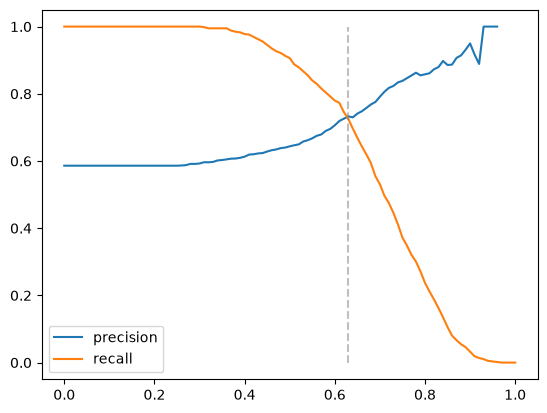

In [32]:
plt.plot(df_score.threshold, df_score.p, label='precision')
plt.plot(df_score.threshold, df_score.r, label='recall')

plt.vlines(0.63, 0, 1, color='grey', linestyle='--', alpha=0.5)

plt.legend()
plt.show()

# Question 4: F1 score


In [33]:
df_score['f1'] = 2 * df_score.p * df_score.r / (df_score.p + df_score.r)
df_score[df_score.f1==df_score['f1'].max()]

,threshold,tp,tn,fp,fn,p,r,f1
41,0.41,572,62,352,14,0.619048,0.976109,0.757616


# Question 5: 5-Fold CV

In [35]:
from sklearn.model_selection import KFold
columns = list(df.columns)
columns.remove('converted')
columns

['lead_source',
 'industry',
 'employment_status',
 'location',
 'annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [38]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[columns].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

def predict(df, dv, model):
    dicts = df[columns].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [39]:
scores = []

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print(f'{np.mean(scores):.3f} +- {np.std(scores):.3f}')

0.732 +- 0.007


# Question 6: Hyperparameter Tuning

In [45]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print(f'{C:.6f}, {np.mean(scores):.3f} +- {np.std(scores):.3f}')

0.000001, 0.617 +- 0.019
0.001000, 0.749 +- 0.010
1.000000, 0.732 +- 0.007
